# Part 1: Model Selection and Architecture Tuning

This notebook follows a two-stage model selection procedure. In the first stage, the CNN is trained on reduced-resolution images to explore a broad architecture space efficiently and identify promising hyperparameter regions.

In the second stage, the strongest configurations are retrained on full-resolution images to assess their generalisation performance under more realistic input conditions. This staged design balances computational efficiency with robust model comparison and is appropriate for image classification tasks in which larger inputs increase both memory usage and training time.


In [1]:
from pathlib import Path
import json

import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_images
from PIL import Image
import keras
import numpy as np
from collections import Counter

import keras_tuner as kt
import pandas as pd


# Utility functions for saving and reloading model histories so that tuning runs can be
# resumed without re-training every candidate from scratch when the notebook is rerun.
def save_history(history, path):
    with open(path, "w") as f:
        json.dump(history.history, f)


def load_history(path):
    with open(path, "r") as f:
        loaded = json.load(f)
    history = tf.keras.callbacks.History()
    history.history = loaded

    return history

In [2]:
# All file paths are resolved relative to the notebook directory so that model checkpoints,
# training histories, and saved configurations remain consistent across reruns.
NOTEBOOK_DIR = Path.cwd()
P1_TRAIN_DIR = NOTEBOOK_DIR / 'part1_train'
P1_VALID_DIR = NOTEBOOK_DIR / 'part1_valid'
P1_TEST_DIR = NOTEBOOK_DIR / 'part1_test'
P2_TRAIN_DIR = NOTEBOOK_DIR / 'part2_train'
P2_VALID_DIR = NOTEBOOK_DIR / 'part2_valid'
P2_TEST_DIR = NOTEBOOK_DIR / 'part2_test'
BASE_MODEL_PATH = NOTEBOOK_DIR / 'CNN_A.keras'
BACKUP_MODEL_PATH = NOTEBOOK_DIR / 'best_full_size_model.keras'
ARTIFACTS_DIR = NOTEBOOK_DIR / 'artifacts'
ARTIFACTS_DIR.mkdir(exist_ok=True)

# Fall back to the backup checkpoint if the final base-model filename is not present.
if not BASE_MODEL_PATH.exists() and BACKUP_MODEL_PATH.exists():
    BASE_MODEL_PATH = BACKUP_MODEL_PATH

print(f'Base model exists: {BASE_MODEL_PATH.exists()}')
print(f'Train directory exists: {P1_TRAIN_DIR.exists()}')
print(f'Validation directory exists: {P1_VALID_DIR.exists()}')
print(f'Test directory exists: {P1_TEST_DIR.exists()}')
print(f'Train directory exists: {P2_TRAIN_DIR.exists()}')
print(f'Validation directory exists: {P2_VALID_DIR.exists()}')
print(f'Test directory exists: {P2_TEST_DIR.exists()}')

# Force CPU before tuner/model creation to avoid Metal GPU timeout errors on macOS.
tf.keras.backend.clear_session()
try:
    tf.config.list_physical_devices("GPU")
    print("Using GPU for model creation and tuning.")
except RuntimeError:
    print("Using CPU for model creation and tuning.")
    pass

plt.rcParams['font.size'] = 14
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['legend.fontsize'] = 12

Base model exists: False
Train directory exists: True
Validation directory exists: True
Test directory exists: True
Train directory exists: True
Validation directory exists: True
Test directory exists: True
Using GPU for model creation and tuning.


### Part 1a: Initial Hyperparameter Tuning  
- Load the train, test and validation sets in a reduced resolution for faster hyperparameter tuning
- Complete hyperparameter tuning on a smaller search space
- Conclude which hyperparameter/structures have been successful

In [3]:
# import the images for tuning 
train_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)
val_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)
test_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

X_train = train_gen.flow_from_directory(
    str(P1_TRAIN_DIR), 
    target_size=(128, 128),
    batch_size=32,

)
X_test = test_gen.flow_from_directory(
    str(P1_TEST_DIR),
    target_size=(128, 128),
    batch_size=32   
)
X_valid = val_gen.flow_from_directory(
    str(P1_VALID_DIR),
    target_size=(128, 128),
    batch_size=32
)

Found 1546 images belonging to 10 classes.
Found 50 images belonging to 10 classes.
Found 50 images belonging to 10 classes.


Text(0.5, 1.0, 'Test Image')

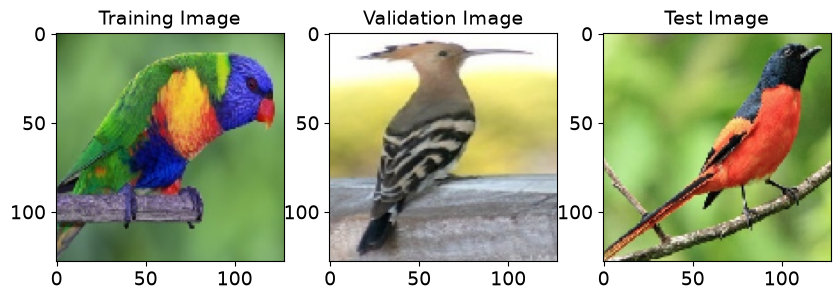

In [4]:
# display the first image in each set
plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(X_train[0][0][0])
plt.title('Training Image')
plt.subplot(1, 3, 2)
plt.imshow(X_valid[0][0][0])
plt.title('Validation Image')
plt.subplot(1, 3, 3)
plt.imshow(X_test[0][0][0])
plt.title('Test Image')

Initial Hyperparameters:  
- number of blocks (1 to 4)
- filter size (32, 64 or 128)
- kernel size (3 or 5)
- dense units (64 or 128)
- learning rate (between 0.0001 and 0.000001)

The some of the hyperparameters chosen will be used for candidates for the final model 

In [5]:
# Reduced-resolution architecture search for the first-stage tuning pass.
# This provides a fast screening stage before committing to the more expensive full-size retraining.
def build_candidate_model(hp):
    inputs = tf.keras.Input(shape=(128, 128, 3))
    x = inputs

    # Search over a compact architecture family: block depth, filter size, kernel size,
    # dense layer width, learning rate, and dropout regularisation.
    for i in range(hp.Int("num_blocks", 1, 4)):
        x = tf.keras.layers.Conv2D(
            hp.Choice(f"filters_{i}", [32, 64, 128]),
            kernel_size=hp.Choice(f"kernel_{i}", [3, 5]),
            padding="same",
            activation="relu"
        )(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(
        hp.Choice("dense_units", [64, 128]),
        activation="relu"
    )(x)
    x = tf.keras.layers.Dropout(
        hp.Float("dropout", 0.2, 0.5, step=0.1)
    )(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Float("learning_rate", 1e-5, 1e-3, sampling="log")
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [ ]:
# %%time
FAST_TUNER_DIR = NOTEBOOK_DIR / "keras_tuner_results" / "image_classifier_fast"
FAST_MODEL_PATH = NOTEBOOK_DIR / "best_fast_model.keras"
FAST_HP_PATH = NOTEBOOK_DIR / "best_fast_hp.json"

# The fast search is intentionally lightweight: it screens promising architectures on
# reduced images before the most competitive candidates are retrained at the final resolution.
tuner = kt.Hyperband(
    build_candidate_model,
    objective="val_accuracy",
    max_epochs=25,
    factor=3,
    directory="keras_tuner_results",
    project_name="image_classifier_fast"
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

if FAST_MODEL_PATH.exists() and FAST_HP_PATH.exists():
    print("Loading the saved best fast-tuning model from disk...")
    best_model = tf.keras.models.load_model(FAST_MODEL_PATH, compile=False)
    with open(FAST_HP_PATH, "r") as f:
        best_hp = kt.HyperParameters.from_config(json.load(f))
    tuner.search(
        X_train,
        validation_data=(X_valid),
        callbacks=[early_stopping]
    )
else:
    tuner.search(
        X_train,
        validation_data=(X_valid),
        callbacks=[early_stopping]
    )
    best_model = tuner.get_best_models(num_models=1)[0]
    best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
    best_model.save(FAST_MODEL_PATH)
    with open(FAST_HP_PATH, "w") as f:
        json.dump(best_hp.get_config(), f)

# If we loaded from disk, keep the tuner object aligned with the saved result.
if not FAST_MODEL_PATH.exists() or not FAST_HP_PATH.exists():
    best_model = tuner.get_best_models(num_models=1)[0]
    best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print(best_model.summary())

# Save the best fast-model architecture as an image for reporting.
try:
    tf.keras.utils.plot_model(
        best_model,
        to_file=str(ARTIFACTS_DIR / "best_fast_model_architecture.png"),
        show_shapes=True,
        show_dtype=False,
        show_layer_names=True,
        rankdir="TB",
        expand_nested=False,
        dpi=150,
    )
    print(f"Saved best fast-model architecture to {ARTIFACTS_DIR / 'best_fast_model_architecture.png'}")
except Exception as e:
    print(f"Could not save best fast-model architecture: {e}")


Trial 1 Complete [00h 00m 27s]
val_accuracy: 0.11999999731779099

Best val_accuracy So Far: 0.11999999731779099
Total elapsed time: 00h 00m 27s

Search: Running Trial #2

Value             |Best Value So Far |Hyperparameter
1                 |2                 |num_blocks
128               |64                |filters_0
3                 |3                 |kernel_0
128               |64                |dense_units
0.2               |0.4               |dropout
0.00072882        |0.00050709        |learning_rate
32                |32                |filters_1
3                 |3                 |kernel_1
3                 |3                 |tuner/epochs
0                 |0                 |tuner/initial_epoch
2                 |2                 |tuner/bracket
0                 |0                 |tuner/round

Epoch 1/3
49/49 ━━━━━━━━━━━━━━━━━━━━ 14s 262ms/step - accuracy: 0.2283 - loss: 2.1534 - val_accuracy: 0.1600 - val_loss: 2.2765
Epoch 2/3
49/49 ━━━━━━━━━━━━━━━━━━━━ 13s 256ms/st

In [ ]:
# Plot the fast tuning results (128x128)
fast_histories = []
trial_scores = []
FAST_TUNING_DIR = NOTEBOOK_DIR / "fast_tuning_candidates"
FAST_TUNING_DIR.mkdir(exist_ok=True)

# Rebuild and train the top 5 fast models to collect learning curves
for i, hp in enumerate(tuner.get_best_hyperparameters(num_trials=3), 1):
    model_path = FAST_TUNING_DIR / f"fast_candidate_{i}.keras"
    history_path = FAST_TUNING_DIR / f"fast_candidate_{i}_history.json"

    if model_path.exists() and history_path.exists():
        print(f"Loading saved fast candidate {i} from disk...")
        model = tf.keras.models.load_model(model_path, compile=False)
        history = load_history(history_path)
    else:
        print(f"Training fast candidate {i}...")
        model = build_candidate_model(hp)
        history = model.fit(
            X_train,
            validation_data=X_valid,
            epochs=25,
            callbacks=[early_stopping],
            verbose=0
        )
        model.save(model_path)
        save_history(history, history_path)

    fast_histories.append(history)
    trial_scores.append((i, max(history.history["val_accuracy"])))

plt.figure(figsize=(10, 6))
colors = plt.cm.Purples(np.linspace(0.35, 0.95, len(fast_histories)))

for i, history in enumerate(fast_histories, 1):
    epochs = np.arange(len(history.history["val_accuracy"]))
    color = colors[i - 1]
    plt.plot(
        epochs,
        history.history["val_accuracy"],
        label=f"Candidate {i} accuracy",
        color=color,
        linewidth=2
    )
    plt.plot(
        epochs,
        history.history["val_loss"],
        linestyle="--",
        label=f"Candidate {i} loss",
        color=color,
        linewidth=2
    )

plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("Fast-model tuning comparison (128x128)")
plt.legend(loc="upper right", fontsize=8, ncol=2)
plt.grid(True)
plt.savefig(ARTIFACTS_DIR / "fast_model_tuning_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 3 fast-model validation accuracies:")
for i, score in trial_scores:
    print(f"Candidate {i}: {score:.4f}")


In [ ]:
# Optional: print the top 5 tuned configurations for reporting
best_hps = tuner.get_best_hyperparameters(num_trials=5)

hp_rows = []
for i, hp in enumerate(best_hps, 1):
    row = {"candidate": i}
    row.update(hp.values)
    hp_rows.append(row)

hp_df = pd.DataFrame(hp_rows)
hp_df


### Interpretation of the Tuning Results

The reduced-resolution tuning stage is intended as a screening mechanism rather than a final performance estimate. Hyperparameter rankings at this stage are informative for identifying promising architectural families, but they are not assumed to be identical to those obtained when training on the full-resolution dataset.

This difference arises because higher spatial resolution changes the feature distribution and can alter the relative effectiveness of network depth, filter size, and regularisation. In particular, deeper architectures may require additional epochs to converge and may not appear among the top-ranked models under a short tuning budget.

For this reason, the final model selection is performed after retraining the most competitive configurations on full-size images, where the validation signal reflects the model’s generalisation behaviour under the final dataset conditions.


## Part 1b: Focused Hyperparameter Tuning

- Compare the strongest configurations identified during the initial search using full-size images.
- Evaluate deeper architectural variants under the final input resolution.

The reduced-resolution search was used to explore the architecture space efficiently. The best-performing configurations are retrained on full-size images to determine the final model for reporting and to assess whether deeper architectures offer a genuine performance improvement under the final image resolution.


In [ ]:
# Load the full-size images for the final model comparison
train_full = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_full = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)
test_full = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

X_train_full = train_full.flow_from_directory(
    str(P1_TRAIN_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

X_test_full = test_full.flow_from_directory(
    str(P1_TEST_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

X_valid_full = val_full.flow_from_directory(
    str(P1_VALID_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)


### Class imbalance handling
The training split is mildly imbalanced, so we use class weighting rather than duplicating images. This approach reduces the influence of majority classes while preserving the original data distribution and avoiding artificial inflation of the training set.

In [ ]:
# Check whether the class distribution is balanced across the dataset.

train_counts = Counter()
valid_counts = Counter()
test_counts = Counter()

for split_name, directory in [('train', P1_TRAIN_DIR), ('valid', P1_VALID_DIR), ('test', P1_TEST_DIR)]:
    for class_dir in sorted(directory.iterdir()):
        if class_dir.is_dir():
            count = len(list(class_dir.glob('*')))
            if split_name == 'train':
                train_counts[class_dir.name] = count
            elif split_name == 'valid':
                valid_counts[class_dir.name] = count
            else:
                test_counts[class_dir.name] = count

print('Train class counts:', dict(train_counts))
print('Validation class counts:', dict(valid_counts))
print('Test class counts:', dict(test_counts))

train_balanced = len(set(train_counts.values())) == 1
valid_balanced = len(set(valid_counts.values())) == 1
test_balanced = len(set(test_counts.values())) == 1

print(f"Train balanced: {train_balanced}")
print(f"Validation balanced: {valid_balanced}")
print(f"Test balanced: {test_balanced}")

# Compute a class-weight dictionary based on the imbalanced training split.
# This down-weights majority classes without duplicating images or altering the
# original dataset distribution.
class_indices = X_train_full.class_indices
class_weights = {}
train_total = sum(train_counts.values())
num_classes = len(train_counts)

for class_name, idx in class_indices.items():
    class_count = train_counts[class_name]
    class_weights[idx] = train_total / (num_classes * class_count)

print("Class weights:", class_weights)


In [ ]:
# display the first image in each set
plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(X_train_full[0][0][0])
plt.title('Training Image')
plt.subplot(1, 3, 2)
plt.imshow(X_valid_full[0][0][0])
plt.title('Validation Image')
plt.subplot(1, 3, 3)
plt.imshow(X_test_full[0][0][0])
plt.title('Test Image')

In [ ]:
top_hps = tuner.get_best_hyperparameters(num_trials=5)
all_histories = []
results = []
trained_full_models = []
FULL_TUNING_DIR = NOTEBOOK_DIR / "full_tuning_candidates"
FULL_TUNING_DIR.mkdir(exist_ok=True)

for i, hp in enumerate(top_hps, 1):
    print(f"\nTraining candidate {i} on full-size data...")
    model_path = FULL_TUNING_DIR / f"candidate_full_{i}.keras"
    history_path = FULL_TUNING_DIR / f"candidate_full_{i}_history.json"

    def build_candidate_model_full():
        inputs = tf.keras.Input(shape=(224, 224, 3))
        x = inputs

        for j in range(hp.get("num_blocks")):
            x = tf.keras.layers.Conv2D(
                hp.get(f"filters_{j}"),
                kernel_size=hp.get(f"kernel_{j}"),
                padding="same",
                activation="relu"
            )(x)
            x = tf.keras.layers.BatchNormalization()(x)
            x = tf.keras.layers.MaxPooling2D()(x)

        x = tf.keras.layers.GlobalAveragePooling2D()(x)
        x = tf.keras.layers.Dense(hp.get("dense_units"), activation="relu")(x)
        x = tf.keras.layers.Dropout(hp.get("dropout"))(x)
        outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

        model = tf.keras.Model(inputs, outputs)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=hp.get("learning_rate")
            ),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )
        return model

    if model_path.exists() and history_path.exists():
        print(f"Loading saved full-size model candidate {i} from disk...")
        model = tf.keras.models.load_model(model_path, compile=False)
        history = load_history(history_path)
    else:
        model = build_candidate_model_full()
        history = model.fit(
            X_train_full,
            validation_data=X_valid_full,
            epochs=50,
            callbacks=[
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=8,
                    restore_best_weights=True
                )
            ],
            class_weight=class_weights,
            verbose=1
        )
        model.save(model_path)
        save_history(history, history_path)

    all_histories.append(history)
    val_acc = max(history.history["val_accuracy"])
    trained_full_models.append((i, model, val_acc))
    print(f"Candidate {i} loaded or trained. Validation accuracy: {val_acc:.4f}")

# Plot the top 5 full-size model comparison
plt.figure(figsize=(10, 6))
colors = plt.cm.Purples(np.linspace(0.35, 0.95, len(all_histories)))

for i, history in enumerate(all_histories, 1):
    epochs = np.arange(len(history.history["val_accuracy"]))
    color = colors[i - 1]
    plt.plot(
        epochs,
        history.history["val_accuracy"],
        label=f"Candidate {i} accuracy",
        color=color,
        linewidth=2
    )
    plt.plot(
        epochs,
        history.history["val_loss"],
        linestyle="--",
        label=f"Candidate {i} loss",
        color=color,
        linewidth=2
    )

plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("Top 5 full-size model comparison")
plt.legend(loc="upper right", fontsize=8, ncol=2)
plt.grid(True)
plt.savefig(ARTIFACTS_DIR / "full_size_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


for item in sorted(results, key=lambda x: x[2], reverse=True):

    print(f"Candidate {item[0]}: val_accuracy={item[2]:.4f}, params={item[1]}")


### Additional architecture check

After examining the results of the tuning, it is clear that the deeper configurations (4 block) perform well on the full size images, however, they require more training and higher patience, so were discarded by the tuner. Also they may have overfit on the smaller images. To assess whether the deeper models required longer training, tuning is done on the 4 block models only with a higher patience and more epochs. 


In [ ]:
# Focused 4-block tuning on full-size images
# This replaces the manual large-model experiment with a proper tuner search.

tf.random.set_seed(42)


def build_four_block_model(hp):
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = inputs

    for i in range(4):
        x = tf.keras.layers.Conv2D(
            hp.Choice(f"filters_{i}", [32, 64, 128, 256]),
            kernel_size=hp.Choice(f"kernel_{i}", [3, 5]),
            padding="same",
            activation="relu"
        )(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(
        hp.Choice("dense_units", [64, 128, 256]),
        activation="relu"
    )(x)
    x = tf.keras.layers.Dropout(
        hp.Float("dropout", 0.2, 0.5, step=0.1)
    )(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Float("learning_rate", 1e-5, 1e-3, sampling="log")
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


tf.keras.backend.clear_session()

four_block_tuner = kt.Hyperband(
    build_four_block_model,
    objective="val_accuracy",
    max_epochs=40,
    factor=3,
    directory="keras_tuner_results",
    project_name="four_block_full_size"
)

four_block_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=16,
    restore_best_weights=True
)

best_four_block_model_path = NOTEBOOK_DIR / "best_four_block_model.keras"
best_four_block_history_path = NOTEBOOK_DIR / "best_four_block_history.json"

if best_four_block_model_path.exists() and best_four_block_history_path.exists():
    print("Loading saved 4-block model from disk...")
    best_four_block_model = tf.keras.models.load_model(best_four_block_model_path, compile=False)
    history_four_block = load_history(best_four_block_history_path)
    four_block_tuner.search(
        X_train_full,
        validation_data=X_valid_full,
        callbacks=[four_block_early_stopping]
    )
    best_four_block_hp = four_block_tuner.get_best_hyperparameters(num_trials=1)[0]
else:
    four_block_tuner.search(
        X_train_full,
        validation_data=X_valid_full,
        callbacks=[four_block_early_stopping]
    )

    best_four_block_hp = four_block_tuner.get_best_hyperparameters(num_trials=1)[0]
    best_four_block_model = build_four_block_model(best_four_block_hp)

    print("Best 4-block hyperparameters:")
    print(best_four_block_hp.values)

    history_four_block = best_four_block_model.fit(
        X_train_full,
        validation_data=X_valid_full,
        epochs=40,
        callbacks=[four_block_early_stopping],
        class_weight=class_weights,
        verbose=1
    )
    best_four_block_model.save(best_four_block_model_path)
    save_history(history_four_block, best_four_block_history_path)

best_val_acc = max(history_four_block.history["val_accuracy"])
print(f"Best 4-block validation accuracy: {best_val_acc:.4f}")

test_loss, test_accuracy = best_four_block_model.evaluate(X_test_full, verbose=0)
print(f"4-block test accuracy: {test_accuracy:.4f}, test loss: {test_loss:.4f}")

# Save the best 4-block model architecture as an image for reporting.
try:
    tf.keras.utils.plot_model(
        best_four_block_model,
        to_file=str(ARTIFACTS_DIR / "best_four_block_model_architecture.png"),
        show_shapes=True,
        show_dtype=False,
        show_layer_names=True,
        rankdir="TB",
        expand_nested=False,
        dpi=150,
    )
    print(f"Saved best 4-block model architecture to {ARTIFACTS_DIR / 'best_four_block_model_architecture.png'}")
except Exception as e:
    print(f"Could not save best 4-block model architecture: {e}")


In [ ]:
# Compare all tuned candidates from the shallow and deep tuning stages in a single table.
# This keeps both tuning approaches together for direct comparison while avoiding duplicate
# labels when the same candidate is repeated in the search history.
all_model_results = []
seen_models = set()

# Add the shallow-tuned candidates.
for i, model, val_acc in trained_full_models:
    test_loss, test_accuracy = model.evaluate(X_test_full, verbose=0)
    row = {
        "model": f"shallow_candidate_{i}",
        "search_stage": "shallow",
        "val_accuracy": val_acc,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
    }
    if row["model"] not in seen_models:
        seen_models.add(row["model"])
        all_model_results.append(row)
        print(f"Shallow candidate {i}: test_accuracy={test_accuracy:.4f}, test_loss={test_loss:.4f}")

# Add the deeper full-size candidates.
for i, hp in enumerate(four_block_tuner.get_best_hyperparameters(num_trials=5), 1):
    model = build_four_block_model(hp)
    test_loss, test_accuracy = model.evaluate(X_test_full, verbose=0)
    row = {
        "model": f"deep_candidate_{i}",
        "search_stage": "deep",
        "val_accuracy": None,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
    }
    if row["model"] not in seen_models:
        seen_models.add(row["model"])
        all_model_results.append(row)
        print(f"Deep candidate {i}: test_accuracy={test_accuracy:.4f}, test_loss={test_loss:.4f}")

comparison_df = pd.DataFrame(all_model_results).sort_values(
    by="test_accuracy",
    ascending=False,
    ignore_index=True
)

print(comparison_df[["model", "search_stage", "test_accuracy", "test_loss", "val_accuracy"]])

# Save the best full-size model to disk for later use in transfer learning.
best_full_model = max(trained_full_models, key=lambda x: x[2])[1]
best_full_model.save(str(BASE_MODEL_PATH))
best_full_model.save(str(BACKUP_MODEL_PATH))

# Save the best full-size model architecture as an image for reporting.
try:
    tf.keras.utils.plot_model(
        best_full_model,
        to_file=str(ARTIFACTS_DIR / "best_full_model_architecture.png"),
        show_shapes=True,
        show_dtype=False,
        show_layer_names=True,
        rankdir="TB",
        expand_nested=False,
        dpi=150,
    )
    print(f"Saved best full-size model architecture to {ARTIFACTS_DIR / 'best_full_model_architecture.png'}")
except Exception as e:
    print(f"Could not save best full-size model architecture: {e}")

## Part 1c: Conclusion

The final model selected for the base classifier was the architecture that achieved the strongest validation performance after retraining on full-size images. This model was then saved as CNN_A.keras and used as the starting point for the transfer-learning stage in Part 2.

The results indicate that the initial reduced-resolution tuning was effective as a screening tool, but the final decision should be based on the full-resolution evaluation because deeper architectures may require longer training and improved optimisation under the larger spatial scale.


# Part 2: Transfer Learning

This section uses the best base model from Part 1 as a feature extractor and adapts it to the bird-classification task through a new classification head. The aim is to retain the representations learned during the earlier model selection stage while refining the final decision layer for the target dataset.


In [ ]:
# Define the data generators for the bird image dataset.
# The selected CNN was trained on the full-resolution input size used in Part 1,
# so the Part 2 generators must match the saved model input shape.
train_gen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)
valid_gen =  tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)
test_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

X_train = train_gen.flow_from_directory(
    str(P2_TRAIN_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True,
)

X_valid = valid_gen.flow_from_directory(
    str(P2_VALID_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False,
)

X_test = test_gen.flow_from_directory(
    str(P2_TEST_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False,
)


In [ ]:
# Check whether the class distribution is balanced across the dataset.

train_counts = Counter()
valid_counts = Counter()
test_counts = Counter()

for split_name, directory in [('train', P2_TRAIN_DIR), ('valid', P2_VALID_DIR), ('test', P2_TEST_DIR)]:
    for class_dir in sorted(directory.iterdir()):
        if class_dir.is_dir():
            count = len(list(class_dir.glob('*')))
            if split_name == 'train':
                train_counts[class_dir.name] = count
            elif split_name == 'valid':
                valid_counts[class_dir.name] = count
            else:
                test_counts[class_dir.name] = count

print('Train class counts:', dict(train_counts))
print('Validation class counts:', dict(valid_counts))
print('Test class counts:', dict(test_counts))

# Compute a class-weight dictionary based on the imbalanced training split.
# This down-weights majority classes without duplicating images or altering the
# original dataset distribution.
class_indices = X_train.class_indices
class_weights = {}
train_total = sum(train_counts.values())
num_classes = len(train_counts)

for class_name, idx in class_indices.items():
    class_count = train_counts[class_name]
    class_weights[idx] = train_total / (num_classes * class_count)

print("Class weights:", class_weights)



In [ ]:
# Visualise a few representative examples from each split.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sample_train = X_train[0][0][0]
sample_valid = X_valid[0][0][0]
sample_test = X_test[0][0][0]

axes[0].imshow(sample_train)
axes[0].set_title('Training image')
axes[0].axis('off')

axes[1].imshow(sample_valid)
axes[1].set_title('Validation image')
axes[1].axis('off')

axes[2].imshow(sample_test)
axes[2].set_title('Test image')
axes[2].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# Load the saved CNN from the previous stage and inspect its structure.
base_model = tf.keras.models.load_model(str(BASE_MODEL_PATH))
base_model.summary()

print(f'Loaded base model from: {BASE_MODEL_PATH}')
print(f'Input shape: {base_model.input_shape}')
print(f'Output shape: {base_model.output_shape}')


In [ ]:
# Build two transfer-learning variants from the same base CNN so they can be compared fairly.
# Variant A keeps the base network frozen and trains only a new classifier head.
# Variant B uses an independent copy of the same base model; its head is trained first and
# then a deeper block of the backbone is unfrozen for fine-tuning at a lower learning rate.
tf.keras.backend.clear_session()


def build_transfer_model(model_path):
    backbone = tf.keras.models.load_model(model_path)
    backbone.trainable = False
    x = backbone.layers[-4].output
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    model = tf.keras.Model(inputs=backbone.input, outputs=outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model


base_transfer_model = build_transfer_model(str(BASE_MODEL_PATH))
deep_transfer_model = build_transfer_model(str(BASE_MODEL_PATH))

# Unfreeze only the deepest part of the independent deep-fine-tuning variant.
base_submodel = deep_transfer_model.layers[1]
base_submodel.trainable = True
for layer in base_submodel.layers[:-2]:
    layer.trainable = False

deep_transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

print("\nBase transfer-learning variant created from the saved base model.")
base_transfer_model.summary()
print("\nIndependent deeper fine-tuning variant created from the same base model.")
deep_transfer_model.summary()

In [ ]:
# Train the head-only transfer model while the base CNN remains frozen.
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
    )
]

base_history = base_transfer_model.fit(
    X_train,
    validation_data=X_valid,
    epochs=20,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1,
)

# Save the standard transfer-learning checkpoint.
TL_MODEL_PATH = NOTEBOOK_DIR / 'CNN_B.keras'
base_transfer_model.save(str(TL_MODEL_PATH))
print(f'Standard transfer-learned model saved to: {TL_MODEL_PATH}')

history = base_history
tl_model = base_transfer_model

print('Head-only transfer learning complete.')
print('Final train accuracy:', base_history.history['accuracy'][-1])
print('Final validation accuracy:', base_history.history['val_accuracy'][-1])


In [ ]:
# Evaluate on the held-out test set.
test_loss, test_acc = tl_model.evaluate(X_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')

# Plot the training curves.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train loss')
axes[0].plot(history.history['val_loss'], label='validation loss')
axes[0].set_title('Loss over epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='train accuracy')
axes[1].plot(history.history['val_accuracy'], label='validation accuracy')
axes[1].set_title('Accuracy over epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "transfer_learning_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# Fine-tune a slightly deeper portion of the base model from an independent copy of the
# base CNN rather than continuing from the head-only transfer model. This keeps the two
# transfer-learning strategies distinct and directly comparable.
base_submodel = deep_transfer_model.layers[1]
base_submodel.trainable = True
for layer in base_submodel.layers[:-2]:
    layer.trainable = False

deep_transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

fine_tune_history = deep_transfer_model.fit(
    X_train,
    validation_data=X_valid,
    epochs=25,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True,
        )
    ],
    class_weight=class_weights,
    verbose=1,
)

# Evaluate both transfer-learning variants on the same held-out test set.
base_test_loss, base_test_acc = base_transfer_model.evaluate(X_test, verbose=0)
deep_test_loss, deep_test_acc = deep_transfer_model.evaluate(X_test, verbose=0)

print(f'Standard transfer-learning test loss: {base_test_loss:.4f}')
print(f'Standard transfer-learning test accuracy: {base_test_acc:.4f}')
print(f'Deeper fine-tuning test loss: {deep_test_loss:.4f}')
print(f'Deeper fine-tuning test accuracy: {deep_test_acc:.4f}')

# Save the deeper fine-tuned model separately for reporting and comparison.
TL_DEEP_MODEL_PATH = NOTEBOOK_DIR / 'CNN_B_deep.keras'
deep_transfer_model.save(str(TL_DEEP_MODEL_PATH))
print(f'Deeper transfer-learned model saved to: {TL_DEEP_MODEL_PATH}')

# Keep the final deep fine-tuned model as the active transfer model for subsequent analysis.
tl_model = deep_transfer_model

comparison_df = pd.DataFrame([
    {
        'approach': 'head_only_transfer',
        'test_loss': base_test_loss,
        'test_accuracy': base_test_acc,
    },
    {
        'approach': 'deeper_fine_tuning',
        'test_loss': deep_test_loss,
        'test_accuracy': deep_test_acc,
    }
]).sort_values('test_accuracy', ascending=False, ignore_index=True)


comparison_df